IndexError: list index out of range

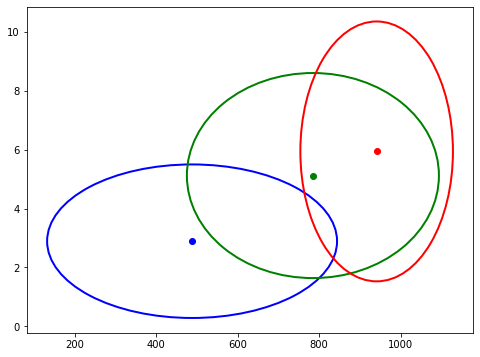

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

# Set random seed for reproducibility
np.random.seed()

# Parameters
mu = 1.5
T = 200
num_trials = 100
thresholds = [5, 6, 7, 8, 9]
pre_change_mean = 0
post_change_mean = mu
std_dev = 1.0
max_time = 1000

# Log-likelihood ratio function for known P = N(0,1), Q = N(mu,1)
def oracle_llr(x, mu):
    return mu * x - 0.5 * mu**2

# Simulate one run of Oracle CuSum
def run_oracle_cusum(threshold, change_time, mu):
    W = 0
    for t in range(max_time):
        if t < change_time:
            x = np.random.normal(pre_change_mean, std_dev)
        else:
            x = np.random.normal(post_change_mean, std_dev)
        llr = oracle_llr(x, mu)
        W = max(0, W + llr)
        if W > threshold:
            return t  # detection time
    return max_time  # did not detect within time

# Collect ARL and Delay stats for different thresholds
results = []

for h in thresholds:
    arl_trials = []
    delay_trials = []
    
    # Under no change (for ARL)
    for _ in range(num_trials):
        W = 0
        for t in range(max_time):
            x = np.random.normal(pre_change_mean, std_dev)
            llr = oracle_llr(x, mu)
            W = max(0, W + llr)
            if W > h:
                arl_trials.append(t)
                break
        else:
            arl_trials.append(max_time)

    # Under change at time T (for delay)
    for _ in range(num_trials):
        tau = run_oracle_cusum(h, T, mu)
        delay_trials.append(tau - T if tau >= T else 0)
    
    arl_mean, arl_std = np.mean(arl_trials), np.std(arl_trials)
    delay_mean, delay_std = np.mean(delay_trials), np.std(delay_trials)
    
    results.append(((arl_mean, delay_mean), (arl_std, delay_std)))

# Plotting function
def plot_ellipse(ax, mean, std, label, color):
    ell = Ellipse(xy=mean, width=2*std[0], height=2*std[1],
                  edgecolor=color, facecolor='none', lw=2, label=label)
    ax.add_patch(ell)
    ax.plot(*mean, 'o', color=color)

# Generate plot
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['blue', 'green', 'red']

for i, ((mean_arl, mean_delay), (std_arl, std_delay)) in enumerate(results):
    plot_ellipse(ax, (mean_arl, mean_delay), (std_arl, std_delay),
                 label=f'h = {thresholds[i]}', color=colors[i])

ax.set_xlabel('Average Run Length (ARL)', fontsize=12)
ax.set_ylabel('Detection Delay', fontsize=12)
ax.set_title('Oracle CuSum: (ARL, Delay) Ellipses', fontsize=14)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()


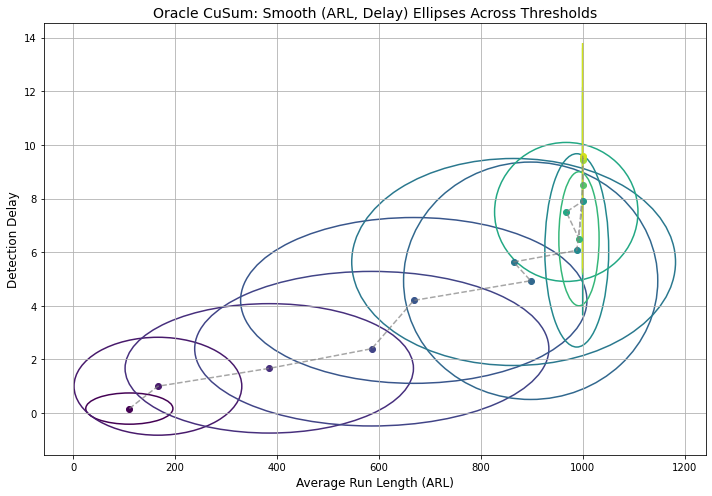

In [1]:
# Re-import necessary libraries after kernel reset
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# Set random seed for reproducibility
np.random.seed(42)

# Parameters
mu = 1.5
T = 200
num_trials_smooth = 30
thresholds_smooth = np.linspace(3.0, 12.0, 15)
pre_change_mean = 0
post_change_mean = mu
std_dev = 1.0
max_time = 1000

# Log-likelihood ratio function
def oracle_llr(x, mu):
    return mu * x - 0.5 * mu**2

# CuSum function under change at time T
def run_oracle_cusum(threshold, change_time, mu):
    W = 0
    for t in range(max_time):
        if t < change_time:
            x = np.random.normal(pre_change_mean, std_dev)
        else:
            x = np.random.normal(post_change_mean, std_dev)
        llr = oracle_llr(x, mu)
        W = max(0, W + llr)
        if W > threshold:
            return t
    return max_time

# Plotting function for ellipses
def plot_ellipse(ax, mean, std, label, color):
    ell = Ellipse(xy=mean, width=2*std[0], height=2*std[1],
                  edgecolor=color, facecolor='none', lw=1.5, label=label)
    ax.add_patch(ell)
    ax.plot(*mean, 'o', color=color)

# Collect results for smooth threshold sweep
results_smooth = []

for h in thresholds_smooth:
    arl_trials = []
    delay_trials = []
    
    for _ in range(num_trials_smooth):
        # ARL
        W = 0
        for t in range(max_time):
            x = np.random.normal(pre_change_mean, std_dev)
            llr = oracle_llr(x, mu)
            W = max(0, W + llr)
            if W > h:
                arl_trials.append(t)
                break
        else:
            arl_trials.append(max_time)
        
        # Delay
        tau = run_oracle_cusum(h, T, mu)
        delay_trials.append(tau - T if tau >= T else 0)
    
    arl_mean, arl_std = np.mean(arl_trials), np.std(arl_trials)
    delay_mean, delay_std = np.mean(delay_trials), np.std(delay_trials)
    
    results_smooth.append(((arl_mean, delay_mean), (arl_std, delay_std)))

# Plot the smooth curve with ellipses
fig, ax = plt.subplots(figsize=(10, 7))
cmap = plt.get_cmap('viridis')

for i, ((mean_arl, mean_delay), (std_arl, std_delay)) in enumerate(results_smooth):
    color = cmap(i / len(results_smooth))
    plot_ellipse(ax, (mean_arl, mean_delay), (std_arl, std_delay),
                 label=f'h = {thresholds_smooth[i]:.1f}', color=color)

# Connect ellipse centers with a line
mean_points = np.array([r[0] for r in results_smooth])
ax.plot(mean_points[:, 0], mean_points[:, 1], linestyle='--', color='gray', alpha=0.7)

ax.set_xlabel('Average Run Length (ARL)', fontsize=12)
ax.set_ylabel('Detection Delay', fontsize=12)
ax.set_title('Oracle CuSum: Smooth (ARL, Delay) Ellipses Across Thresholds', fontsize=14)
ax.grid(True)
plt.tight_layout()
plt.show()
